# Seismotectonic analysis of Pakistan: earthquakes, plate boundaries and volcanoes

Run this notebook top to bottom on Google Colab (Runtime, then Run all). It needs an internet connection.

**Data (all open):** USGS earthquake catalog (ComCat), PB2002 plate boundaries (Bird, 2003), Natural Earth country borders. Optional: Smithsonian Global Volcanism Program list.

**Questions**
1. Where do earthquakes concentrate in and around Pakistan, and how does that line up with plate boundaries?
2. How deep are they, and where is the deep (intermediate-depth) seismicity?
3. What is the magnitude-frequency relationship (Gutenberg-Richter b-value), with uncertainty?
4. Is the catalog complete over time, and how has the rate changed?
5. Are earthquakes closer to plate boundaries than a random scatter of points would be (Monte Carlo test)?

**Validity choices:** completeness magnitude (Mc) is estimated before any statistics; statistics use a declustered catalog (Gardner and Knopoff, 1974) so aftershock swarms do not dominate; distances and densities are computed in an equal-area projection, not raw degrees.

In [28]:
sh = main[(main.mag >= Mc) & (main.depth <= 40)]
d_sh = sh.geometry.distance(bu).values / 1000
meds = np.array([np.median(RNG.choice(rand, len(d_sh))) for _ in range(5000)])
p_closer = (np.sum(meds <= np.median(d_sh)) + 1) / 5001
print(len(d_sh), "shallow events | median km:", round(np.median(d_sh)), "vs random", round(np.median(rand)), "| p(closer) =", round(p_closer, 4))
print({k: f"{100*(d_sh<=k).mean():.1f}% vs {100*(rand<=k).mean():.1f}% random" for k in (50, 100, 200)})

1691 shallow events | median km: 259 vs random 243 | p(closer) = 0.9864
{50: '16.7% vs 12.3% random', 100: '30.6% vs 22.9% random', 200: '44.4% vs 42.0% random'}


In [29]:
!pip -q install geopandas shapely pyproj
import io, os, json, warnings, datetime as dt
import numpy as np, pandas as pd, geopandas as gpd, requests, shapely
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10})
RNG = np.random.default_rng(42)

START_YEAR = 1973                   # USGS global coverage is reasonably consistent from about 1973
FETCH_BBOX = (59, 22, 80, 40)       # lon_min, lat_min, lon_max, lat_max
MIN_MAG = 4.0
BUFFER_KM = 300                     # study region = Pakistan plus this buffer (captures Hindu Kush, Makran, Pamir edge)
PROJ = "+proj=aea +lat_1=25 +lat_2=35 +lat_0=30 +lon_0=69 +datum=WGS84 +units=m +no_defs"  # equal-area

In [30]:
# 1. Download the earthquake catalog from USGS in 3-year chunks
URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
today = dt.date.today()
def fetch(start, end):
    p = dict(format="csv", starttime=start, endtime=end, minmagnitude=MIN_MAG, orderby="time-asc",
             minlongitude=FETCH_BBOX[0], minlatitude=FETCH_BBOX[1], maxlongitude=FETCH_BBOX[2], maxlatitude=FETCH_BBOX[3])
    r = requests.get(URL, params=p, timeout=180); r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text)) if r.text.strip() else pd.DataFrame()

frames = []
for y in range(START_YEAR, today.year + 1, 3):
    s = f"{y}-01-01"
    e = f"{y+3}-01-01" if y + 3 <= today.year else today.isoformat()
    df = fetch(s, e); frames.append(df); print(s, "to", e, "->", len(df), "events")

eq = pd.concat(frames, ignore_index=True).drop_duplicates("id")
eq = eq[eq["type"].eq("earthquake")].dropna(subset=["mag", "latitude", "longitude", "depth"]).copy()
eq["time"] = pd.to_datetime(eq["time"], utc=True)
print("Total events downloaded:", len(eq), "| period:", eq.time.min().date(), "to", eq.time.max().date())

1973-01-01 to 1976-01-01 -> 494 events
1976-01-01 to 1979-01-01 -> 482 events
1979-01-01 to 1982-01-01 -> 479 events
1982-01-01 to 1985-01-01 -> 517 events
1985-01-01 to 1988-01-01 -> 659 events
1988-01-01 to 1991-01-01 -> 621 events
1991-01-01 to 1994-01-01 -> 620 events
1994-01-01 to 1997-01-01 -> 603 events
1997-01-01 to 2000-01-01 -> 860 events
2000-01-01 to 2003-01-01 -> 901 events
2003-01-01 to 2006-01-01 -> 1119 events
2006-01-01 to 2009-01-01 -> 1329 events
2009-01-01 to 2012-01-01 -> 587 events
2012-01-01 to 2015-01-01 -> 981 events
2015-01-01 to 2018-01-01 -> 1287 events
2018-01-01 to 2021-01-01 -> 1012 events
2021-01-01 to 2024-01-01 -> 1131 events
2024-01-01 to 2026-10-18 -> 984 events
Total events downloaded: 14662 | period: 1973-01-02 to 2026-10-17


In [31]:
# 2. Borders, plate boundaries, study region
BOUND_URL = "https://raw.githubusercontent.com/fraxen/tectonicplates/master/GeoJSON/PB2002_boundaries.json"
bound = gpd.read_file(BOUND_URL).to_crs(PROJ)
try:
    countries = gpd.read_file("https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip")
except Exception:
    countries = gpd.read_file("https://raw.githubusercontent.com/datasets/geo-countries/master/data/countries.geojson")
name_col = next(c for c in ["NAME", "ADMIN", "name"] if c in countries.columns)
countries = countries.to_crs(PROJ)
pak = countries[countries[name_col] == "Pakistan"]
assert len(pak) > 0, "Pakistan not found in the borders file; check the name column."
study = pak.buffer(BUFFER_KM * 1000).unary_union
bound_in = bound[bound.intersects(study)]

g = gpd.GeoDataFrame(eq, geometry=gpd.points_from_xy(eq.longitude, eq.latitude), crs=4326).to_crs(PROJ)
g = g[g.within(study)].copy()
print("Events inside the study region:", len(g))
print("Magnitude types in catalog:", g.magType.value_counts().head(4).to_dict())

Events inside the study region: 13418
Magnitude types in catalog: {'mb': 12581, 'mwc': 279, 'mww': 193, 'mw': 158}


In [32]:
# 3. Completeness magnitude (Mc) by maximum curvature + 0.2 (Woessner and Wiemer, 2005), then decluster
vals, cnt = np.unique(np.round(g.mag.values, 1), return_counts=True)
Mc = round(vals[np.argmax(cnt)] + 0.2, 1)
print("Mc =", Mc)
cat = g[g.mag >= Mc - 1e-9].copy()

def decluster_gk(df):
    """Gardner and Knopoff (1974) windows. Returns df with a boolean 'dependent' column."""
    d = df.sort_values("mag", ascending=False).reset_index(drop=True)
    m = d.mag.values
    t = ((d.time - d.time.min()).dt.total_seconds() / 86400).values
    x = d.geometry.x.values / 1000; y = d.geometry.y.values / 1000
    flag = np.zeros(len(d), bool)
    for i in range(len(d)):
        if flag[i]: continue
        R = 10 ** (0.1238 * m[i] + 0.983)
        T = 10 ** (0.032 * m[i] + 2.7389) if m[i] >= 6.5 else 10 ** (0.5409 * m[i] - 0.547)
        near = (np.hypot(x - x[i], y - y[i]) <= R) & (np.abs(t - t[i]) <= T)
        near[i] = False
        flag |= near & (m <= m[i])
    d["dependent"] = flag
    return d

dec = decluster_gk(cat)
main = dec[~dec.dependent].copy()
print(f"Catalog M>={Mc}: {len(cat)} events | after declustering: {len(main)} independent events ({len(main)/len(cat):.0%})")

Mc = 4.4
Catalog M>=4.4: 7493 events | after declustering: 2673 independent events (36%)


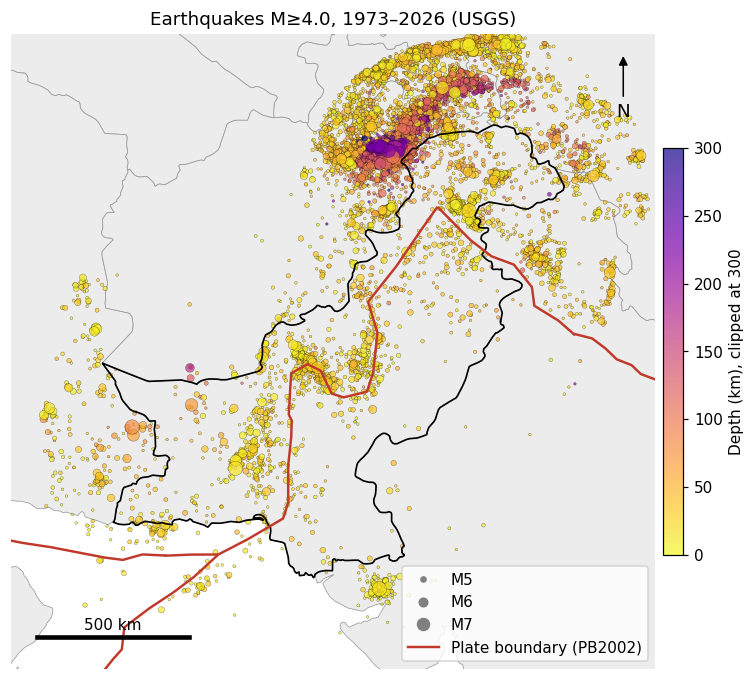

In [33]:
# 4. Helpers and Map 1: epicentres by depth and magnitude
minx, miny, maxx, maxy = gpd.GeoSeries([study], crs=PROJ).total_bounds
W, H = maxx - minx, maxy - miny

def basemap(ax, fill=True):
    countries.plot(ax=ax, facecolor="#ececec" if fill else "none", edgecolor="#9a9a9a", linewidth=0.5, zorder=1)
    pak.boundary.plot(ax=ax, color="black", linewidth=1.1, zorder=4)
    bound_in.plot(ax=ax, color="#c0392b", linewidth=1.6, zorder=5)
    ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy); ax.set_axis_off()
    x0, y0 = minx + 0.04 * W, miny + 0.05 * H
    ax.plot([x0, x0 + 500e3], [y0, y0], "k", lw=3, zorder=6); ax.text(x0 + 250e3, y0 + 0.012 * H, "500 km", ha="center", zorder=6)
    ax.annotate("N", xy=(maxx - 0.05 * W, maxy - 0.03 * H), xytext=(maxx - 0.05 * W, maxy - 0.13 * H),
                arrowprops=dict(arrowstyle="-|>", color="k"), ha="center", fontsize=12, zorder=6)

fig, ax = plt.subplots(figsize=(9, 8))
basemap(ax)
o = g.sort_values("mag")
sc = ax.scatter(o.geometry.x, o.geometry.y, c=o.depth.clip(0, 300), s=np.clip((o.mag - 3.5) ** 2 * 5, 3, 300),
                cmap="plasma_r", alpha=0.7, linewidths=0.2, edgecolors="k", zorder=3)
cb = plt.colorbar(sc, ax=ax, shrink=0.6, pad=0.01); cb.set_label("Depth (km), clipped at 300")
hs = [Line2D([], [], marker="o", ls="", color="grey", markersize=np.sqrt(np.clip((m - 3.5) ** 2 * 5, 3, 300)), label=f"M{m}") for m in (5, 6, 7)]
hs.append(Line2D([], [], color="#c0392b", lw=1.6, label="Plate boundary (PB2002)"))
ax.legend(handles=hs, loc="lower right", frameon=True)
ax.set_title(f"Earthquakes M≥{MIN_MAG}, {eq.time.min().year}–{eq.time.max().year} (USGS)")
fig.savefig("figures/map1_epicentres_depth.png", bbox_inches="tight"); plt.show()

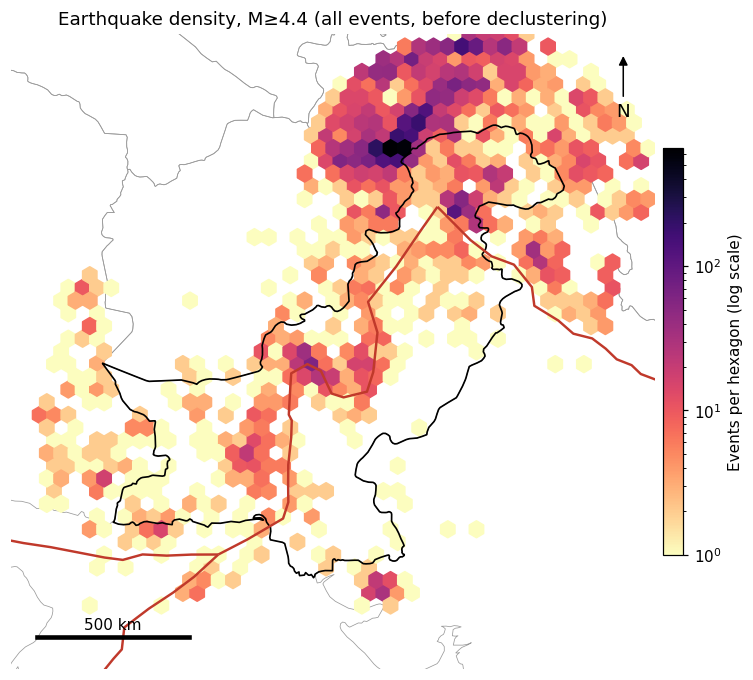

In [34]:
# 5. Map 2: earthquake density (events per equal-area hexagon), complete part of the catalog only (M>=Mc)
fig, ax = plt.subplots(figsize=(9, 8))
hb = ax.hexbin(cat.geometry.x, cat.geometry.y, gridsize=45, bins="log", mincnt=1, cmap="magma_r",
               extent=(minx, maxx, miny, maxy), zorder=2)
basemap(ax, fill=False)
cb = plt.colorbar(hb, ax=ax, shrink=0.6, pad=0.01); cb.set_label("Events per hexagon (log scale)")
ax.set_title(f"Earthquake density, M≥{Mc} (all events, before declustering)")
fig.savefig("figures/map2_density.png", bbox_inches="tight"); plt.show()

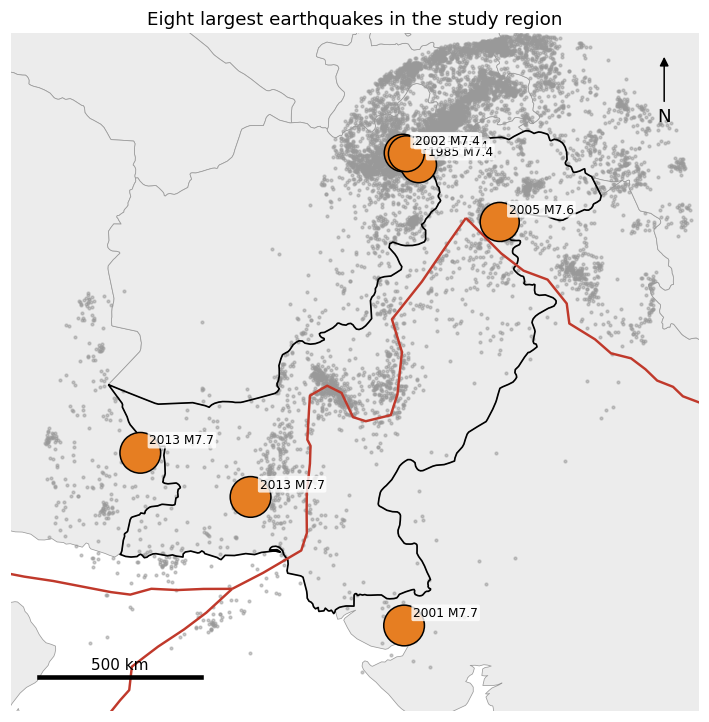

,time,mag,magType,depth,place
5579,2001-01-26,7.7,mwc,16.0,"17 km NW of Bhach?u, India"
9614,2013-04-16,7.7,mww,80.0,"79 km ESE of Kh?sh, Iran"
9776,2013-09-24,7.7,mww,15.0,"113 km NW of Bela, Pakistan"
6978,2005-10-08,7.6,mwc,26.0,"21 km NNE of Muzaffar?b?d, Pakistan"
10567,2015-10-26,7.5,mww,231.0,"Hindu Kush region, Afghanistan"
1756,1983-12-30,7.4,mw,214.5,"55 km S of Jurm, Afghanistan"
2084,1985-07-29,7.4,mw,98.7,"75 km S of Jurm, Afghanistan"
5974,2002-03-03,7.4,mwc,225.6,"51 km SW of Jurm, Afghanistan"


In [35]:
# 6. Map 3: the largest earthquakes
big = g.nlargest(8, "mag")
fig, ax = plt.subplots(figsize=(9, 8))
basemap(ax)
ax.scatter(g.geometry.x, g.geometry.y, s=3, color="#999999", alpha=0.5, zorder=2)
ax.scatter(big.geometry.x, big.geometry.y, s=(big.mag - 4) ** 3 * 14, facecolor="#e67e22", edgecolor="k", zorder=7)
for _, r in big.iterrows():
    ax.annotate(f"{r.time.year} M{r.mag:.1f}", (r.geometry.x, r.geometry.y), xytext=(6, 6), textcoords="offset points", fontsize=8, zorder=8,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
ax.set_title("Eight largest earthquakes in the study region")
fig.savefig("figures/map3_largest_events.png", bbox_inches="tight"); plt.show()
top = big[["time", "mag", "magType", "depth", "place"]].assign(time=lambda d: d.time.dt.date)
top.to_csv("results/largest_events.csv", index=False); top

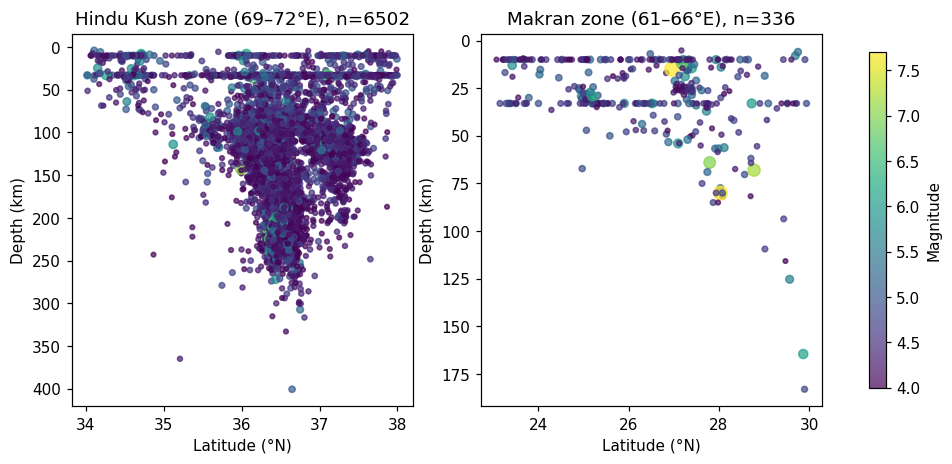

In [36]:
# 7. Depth versus latitude in two seismic zones
zones = [("Hindu Kush zone (69–72°E)", (69, 72), (34, 38)), ("Makran zone (61–66°E)", (61, 66), (23, 30))]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (title, lon, lat) in zip(axs, zones):
    s = eq[eq.longitude.between(*lon) & eq.latitude.between(*lat)]
    sc = ax.scatter(s.latitude, s.depth, c=s.mag, s=8 + (s.mag - 3.5) ** 2 * 4, cmap="viridis", alpha=0.7)
    ax.invert_yaxis(); ax.set_title(f"{title}, n={len(s)}"); ax.set_xlabel("Latitude (°N)"); ax.set_ylabel("Depth (km)")
plt.colorbar(sc, ax=axs, label="Magnitude", shrink=0.9)
fig.savefig("figures/fig4_depth_sections.png", bbox_inches="tight"); plt.show()

n=2673  Mc=4.4  b=1.02 ± 0.02  (95% bootstrap CI 0.98–1.05)  a=7.90


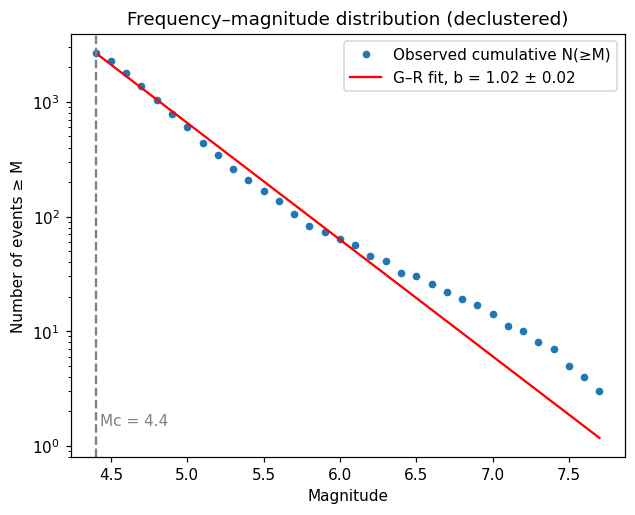

In [37]:
# 8. Gutenberg-Richter law on the declustered catalog (Aki-Utsu maximum likelihood, bootstrap CI)
dm = 0.1
m = np.round(main.mag.values, 1); m = m[m >= Mc - 1e-9]
def b_aki(m):
    return np.log10(np.e) / (m.mean() - (Mc - dm / 2))
b = b_aki(m); n = len(m)
se = 2.30 * b ** 2 * np.sqrt(((m - m.mean()) ** 2).sum() / (n * (n - 1)))   # Shi and Bolt (1982)
boot = np.array([b_aki(RNG.choice(m, n)) for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
a = np.log10(n) + b * Mc
print(f"n={n}  Mc={Mc}  b={b:.2f} ± {se:.2f}  (95% bootstrap CI {lo:.2f}–{hi:.2f})  a={a:.2f}")

mags = np.arange(Mc, m.max() + dm, dm)
cum = np.array([(m >= x - 1e-9).sum() for x in mags])
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.semilogy(mags, cum, "o", ms=4, label="Observed cumulative N(≥M)")
ax.semilogy(mags, 10 ** (a - b * mags), "r-", label=f"G–R fit, b = {b:.2f} ± {se:.2f}")
ax.axvline(Mc, ls="--", color="grey"); ax.text(Mc + 0.03, 1.5, f"Mc = {Mc}", color="grey")
ax.set_xlabel("Magnitude"); ax.set_ylabel("Number of events ≥ M"); ax.legend(); ax.set_title("Frequency–magnitude distribution (declustered)")
fig.savefig("figures/fig5_gutenberg_richter.png", bbox_inches="tight"); plt.show()

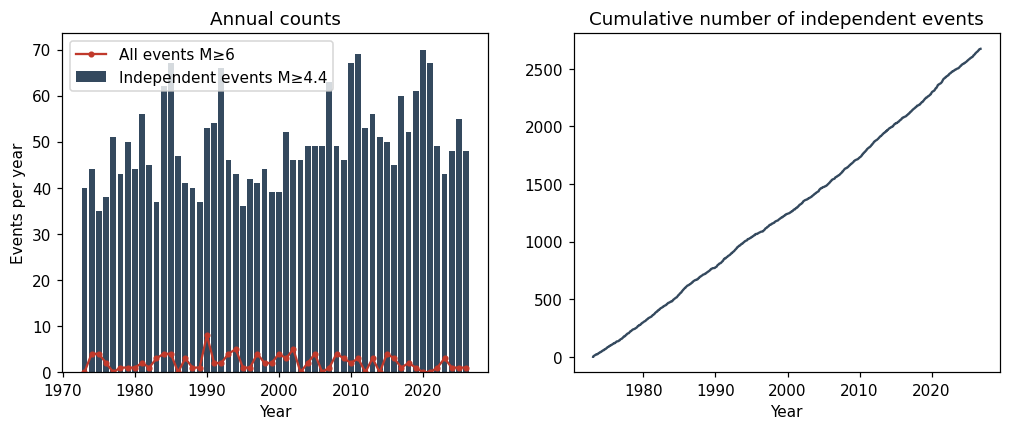

In [38]:
# 9. Temporal behaviour: annual rate and cumulative count (a kinked curve hints at catalog changes)
yr = main[main.mag >= Mc].groupby(main.time.dt.year).size()
yr6 = g[g.mag >= 6].groupby(g.time.dt.year).size().reindex(yr.index, fill_value=0)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].bar(yr.index, yr.values, color="#34495e", label=f"Independent events M≥{Mc}")
axs[0].plot(yr6.index, yr6.values, "o-", color="#c0392b", ms=3, label="All events M≥6")
axs[0].set_xlabel("Year"); axs[0].set_ylabel("Events per year"); axs[0].legend(); axs[0].set_title("Annual counts")
t = main[main.mag >= Mc].sort_values("time")
axs[1].plot(t.time, np.arange(1, len(t) + 1), color="#34495e"); axs[1].set_title("Cumulative number of independent events"); axs[1].set_xlabel("Year")
fig.savefig("figures/fig6_time.png", bbox_inches="tight"); plt.show()

Median distance to nearest plate boundary: observed 294 km vs random 243 km
Monte Carlo p = 1.0000 | KS D = 0.10, p = 5.2e-20 | n events = 2673


,band_km,observed_%,random_%
0,50,11.6,12.3
1,100,22.1,22.9
2,200,34.0,42.0


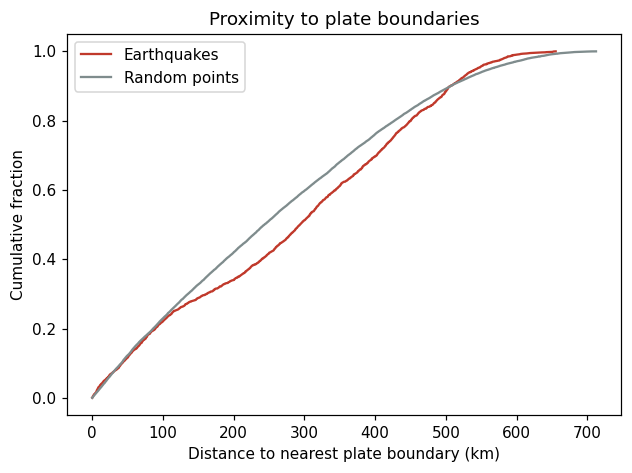

In [39]:
# 10. Are earthquakes closer to plate boundaries than random? Monte Carlo test on independent events
bu = bound_in.unary_union
obs = main[main.mag >= Mc].geometry.distance(bu).values / 1000          # km

def random_points(poly, n):
    x0, y0, x1, y1 = poly.bounds; out = []
    while sum(len(o) for o in out) < n:
        x = RNG.uniform(x0, x1, n); y = RNG.uniform(y0, y1, n)
        ok = shapely.contains_xy(poly, x, y); out.append(np.c_[x[ok], y[ok]])
    return np.vstack(out)[:n]

rp = random_points(study, 20000)
rand = gpd.GeoSeries(gpd.points_from_xy(rp[:, 0], rp[:, 1]), crs=PROJ).distance(bu).values / 1000
meds = np.array([np.median(RNG.choice(rand, len(obs))) for _ in range(5000)])
p_mc = (np.sum(meds <= np.median(obs)) + 1) / (len(meds) + 1)
ks = stats.ks_2samp(obs, rand)
bands = [50, 100, 200]
tab = pd.DataFrame({"band_km": bands,
                    "observed_%": [100 * (obs <= k).mean() for k in bands],
                    "random_%": [100 * (rand <= k).mean() for k in bands]}).round(1)
print(f"Median distance to nearest plate boundary: observed {np.median(obs):.0f} km vs random {np.median(rand):.0f} km")
print(f"Monte Carlo p = {p_mc:.4f} | KS D = {ks.statistic:.2f}, p = {ks.pvalue:.2g} | n events = {len(obs)}")
display(tab)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for d, lab, c in [(obs, "Earthquakes", "#c0392b"), (rand, "Random points", "#7f8c8d")]:
    x = np.sort(d); ax.plot(x, np.arange(1, len(x) + 1) / len(x), label=lab, color=c)
ax.set_xlabel("Distance to nearest plate boundary (km)"); ax.set_ylabel("Cumulative fraction"); ax.legend(); ax.set_title("Proximity to plate boundaries")
fig.savefig("figures/fig7_boundary_distance.png", bbox_inches="tight"); plt.show()

In [40]:
# 11. OPTIONAL: volcanoes. Download the Holocene volcano list from https://volcano.si.edu (Volcano Search, export as CSV), then run this cell.
# Pakistan has very few volcanoes, so treat this as regional context (e.g. the arc near the Pakistan–Iran border). Check the list yourself.
from google.colab import files
up = files.upload()
if up:
    fn = list(up)[0]
    SKIP = 1   # the Smithsonian export has a title row above the header; set to 0 if yours does not
    v = pd.read_csv(fn, skiprows=SKIP)
    latc = next(c for c in v.columns if "lat" in c.lower()); lonc = next(c for c in v.columns if "lon" in c.lower())
    vg = gpd.GeoDataFrame(v, geometry=gpd.points_from_xy(v[lonc], v[latc]), crs=4326).to_crs(PROJ)
    vg = vg[vg.within(study)]
    vg["km_to_plate_boundary"] = (vg.geometry.distance(bu) / 1000).round(0)
    print(len(vg), "volcanoes in the study region")
    fig, ax = plt.subplots(figsize=(9, 8)); basemap(ax)
    ax.scatter(cat.geometry.x, cat.geometry.y, s=2, color="#999999", alpha=0.4, zorder=2)
    ax.scatter(vg.geometry.x, vg.geometry.y, marker="^", s=70, color="#27ae60", edgecolor="k", zorder=7, label="Volcanoes (GVP)")
    ax.legend(loc="lower right"); ax.set_title("Volcanoes, earthquakes and plate boundaries")
    fig.savefig("figures/map8_volcanoes.png", bbox_inches="tight"); plt.show()
    vg.drop(columns="geometry").to_csv("results/volcanoes_in_region.csv", index=False)

In [41]:
for k in (50, 100, 200):
    hits = int((d_sh <= k).sum()); p0 = (rand <= k).mean()
    r = stats.binomtest(hits, len(d_sh), p0, alternative="greater")
    print(f"within {k} km: {hits}/{len(d_sh)} = {100*hits/len(d_sh):.1f}% vs {100*p0:.1f}% random | ratio {hits/len(d_sh)/p0:.2f} | p = {r.pvalue:.3g}")

within 50 km: 283/1691 = 16.7% vs 12.3% random | ratio 1.37 | p = 4.68e-08
within 100 km: 517/1691 = 30.6% vs 22.9% random | ratio 1.33 | p = 2.8e-13
within 200 km: 750/1691 = 44.4% vs 42.0% random | ratio 1.06 | p = 0.0259


In [42]:
# 12. Save a results summary and download everything
summary = {"period": f"{eq.time.min().date()} to {eq.time.max().date()}", "events_M>=4_in_region": int(len(g)), "Mc": float(Mc),
           "events_M>=Mc": int(len(cat)), "independent_events_after_declustering": int(len(main)),
           "b_value": round(float(b), 3), "b_se": round(float(se), 3), "b_95CI": [round(float(lo), 2), round(float(hi), 2)],
           "median_km_to_boundary_observed": round(float(np.median(obs)), 1), "median_km_to_boundary_random": round(float(np.median(rand)), 1),
           "monte_carlo_p": round(float(p_mc), 4)}
json.dump(summary, open("results/summary.json", "w"), indent=2); print(json.dumps(summary, indent=2))
tab.to_csv("results/boundary_distance_bands.csv", index=False)
!zip -qr seismotectonic_outputs.zip figures results
try:
    from google.colab import files; files.download("seismotectonic_outputs.zip")
except Exception: pass

{
  "period": "1973-01-02 to 2026-10-17",
  "events_M>=4_in_region": 13418,
  "Mc": 4.4,
  "events_M>=Mc": 7493,
  "independent_events_after_declustering": 2673,
  "b_value": 1.018,
  "b_se": 0.019,
  "b_95CI": [
    0.98,
    1.05
  ],
  "median_km_to_boundary_observed": 293.8,
  "median_km_to_boundary_random": 243.4,
  "monte_carlo_p": 1.0
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Reading your results (write what your plots show, not what you expect)

Things worth checking against the literature before you write them up: intermediate-depth seismicity under the Hindu Kush; the Makran subduction zone in the southwest; seismicity along the Himalayan front in the north; the large events listed in your table (compare each with its USGS event page). Report the b-value with its uncertainty, state Mc, and say the plate boundary model is coarse (tens of km of positional uncertainty), so the 50 km band is approximate.

**Limits to state in your README:** the USGS catalog mixes magnitude types; completeness varies in space and time; PB2002 is a global model and does not include every active fault; the Monte Carlo test shows association, not cause.